# Step 7 – Interferometry: coherence and interferograms

For every stack, every **pair** of the primary with a secondary acquisition, and every polarisation (HH, HV, VH, VV), the complex interferometric coherence is computed:

$$\gamma = \frac{\langle s_1 s_2^* \rangle}{\sqrt{\langle \lvert s_1\rvert^2\rangle\,\langle \lvert s_2\rvert^2\rangle}}$$

where $s_1$ is the primary SLC, $s_2$ the secondary SLC, $^*$ the complex conjugate and $\langle\cdot\rangle$ the average over a window (multilook, here a boxcar of ~`WINDOW_M` metres, subsampled by half the window).

| Map | Formula | Meaning |
|---|---|---|
| **coherence** | $\lvert\gamma\rvert$, 0 … 1 (grey scale) | how similar the two acquisitions are: 1 = identical, 0 = unrelated. Decreases with time between the acquisitions (changes in the scene), with the spatial baseline and in volume scattering |
| **interferogram** | $\arg\gamma$, −π … π (cyclic colour scale, as in SNAP) | phase difference between the two acquisitions: geometry (if not flattened), atmosphere/ionosphere, motion and structure of the scene |

**Phase and displacement.** A phase difference $\varphi$ corresponds to a displacement along the line of sight of $d = \varphi\,\lambda / 4\pi$. With the BIOMASS wavelength λ ≈ 0.69 m, 1 rad ≈ 55 mm. The phase statistics of every pair are printed in both units.

**Phase flattening and calibration.** The BIOMASS L1C stack products are coregistered on the primary but **not flattened**: the SLC phases still contain the geometric phase, which shows up as dense fringes and also lowers the coherence (the phase rotates within the averaging window). The LUT of every product contains:
- the **flattening phase** (`coregistration_flatteningPhaseScreen`): the geometric phase, removed with `PHASE_CORRECTION = "flattening"` (default): $s \cdot e^{j\phi_{flat}}$
- the **SKP calibration screen** (`skpPhaseCalibration_skpCalibrationPhaseScreen`): large-scale residual phases, e.g. the ionosphere. It is estimated (`skpPhaseCalibrationFlag = true`) but not applied to the data (`skpPhaseCorrectionFlag = false`). `PHASE_CORRECTION = "flattening+calibration"` also removes it: $s \cdot e^{j(\phi_{flat} - \phi_{cal})}$. What remains is the phase that neither the geometry nor the large-scale screen explains, e.g. local ice motion.

`"none"` keeps the raw phases (only for comparison). With `"flattening"`, the interferogram should resemble ESA's own quicklook (see 7.5) and the coherence ESA's LUT coherence.

**Outputs per stack** (in `<run folder>/<stack folder>/interferometry/`):
- one figure per polarisation: a column per pair, interferogram on top, coherence below (`<stack>_<pol>_interferometry.png`)
- a 2-band GeoTIFF per pair and polarisation: coherence and phase in degrees (`<primary date>_<secondary date>_<pol>_insar.tif`)
- a table with the coherence and phase statistics of every pair (`<stack>_coherence_summary.csv`): mean and median coherence; mean phase in rad and mm, phase standard deviation and 2nd/98th percentile (only pixels with coherence ≥ 0.3)

**Diagnostics** (7.5, in `<run folder>/<stack folder>/insar_diagnostics/`): shows what the processing has done to the phase. It prints all processing flags and LUT layers, and shows the flattening phase and SKP calibration screen of every acquisition (`<stack>_lut_phases.png`) and ESA's own interferogram and coherence quicklooks (`<stack>_esa_quicklooks.png`).

**Output folders**: every run gets its own folder with a time stamp, so earlier results are never overwritten. Inside it, the folders mirror the input folders, so every result can be traced back to its product:
`<OUTPUT_DIR>/<date_time>_<analysis>[_<label>]/<stack folder>/L1C/<product>/<product>_<analysis>.png` (and `.tif`).
Each run folder has a `run_info.json` (settings and scenes of the run), and each stack folder a `stack_info.json` (stack ID, primary, what has been processed).

**How to use**
0. First time only: run **7.0** to install the packages, then restart the kernel.
1. Set `DATA_DIR` and `OUTPUT_DIR` in **7.1**, then run **7.1** and **7.2**: they load the tools and list all stacks (with their stack ID) and scenes (★ = primary).
2. Fill in **7.3 Settings**: which stacks and scenes to process.
3. Run **7.4**.
4. Optional: run **7.5** to check the phase processing.

`BiomassProduct.py` (ESA) and `polsar_utils.py` must be in the same folder as this notebook.

## 7.0 First time only: install the packages
Run once, then restart the kernel (**Kernel → Restart Kernel**). `--user` installs them in your home folder, so they are kept when the server restarts. Skip this cell if 7.1 runs without errors.

In [11]:
%pip install --user netCDF4 xarray folium shapely pillow

Note: you may need to restart the kernel to use updated packages.


## 7.1 Load the tools and choose the folders
- `DATA_DIR`: the folder that contains your stacks. It can be a folder on your computer or a cloud bucket mounted as a folder. Leave it as `None` to search automatically.
- `OUTPUT_DIR`: the main folder for all results. It is created if it does not exist; `~` is your home folder.

In [12]:
%matplotlib inline
import polsar_utils as pu

DATA_DIR = "/home/jovyan/shared-buckets/6e08893c-463e-498b-92d2-6761dd17160d/biomass_inputs"  # e.g. "/path/to/biomass_inputs"; None = search automatically
OUTPUT_DIR = "/home/jovyan/idas_dump/test/Nivlisen"  # main folder for all result

## 7.2 Overview of the data

In [13]:
stacks = pu.find_stacks(DATA_DIR)
pu.print_overview(stacks)

8 stack(s), 55 scene(s)

[0] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS  (6 scenes)
      [0] 2026-07-04 16:11             BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
      [1] 2026-07-07 16:11             BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
      [2] 2026-07-10 16:11             BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
      [3] 2026-07-13 16:11  ★ primary  BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
      [4] 2026-07-19 16:11             BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
      [5] 2026-07-22 16:11             BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
[1] BIO_S1_STA__ID_20260915T214352_20261003T214425_T_G01_M05_S0720_W0730_D_02_DZ1NQJ  (7 scenes)
      [0] 2026-09-15 21:43             BIO_S1_STA__1S_2026091

## 7.3 Settings
**Which data**
- `STACKS`: `"all"`, stack names such as `["stack_02"]`, stack IDs (the full ID or just its end, e.g. `["DZ1NQJ"]`), or numbers from the list in 7.2 such as `[0, 2]`
- `SECONDARIES`: `"all"` (every scene except the primary), dates such as `["2026-09-18"]`, or numbers from the list in 7.2 such as `[0, 6]`
- `POLARISATIONS`: any of `["HH", "HV", "VH", "VV"]`

**Where the results go** (inside `OUTPUT_DIR` from 7.1)
- `NEW_RUN_FOLDER`: `True` = a new folder with a time stamp for every run (nothing is overwritten); `False` = write directly in `OUTPUT_DIR`
- `RUN_LABEL`: optional name added to the run folder, e.g. `"window500"`

**Processing**
- `WINDOW_M`: averaging window in metres (300 m as in the reference notebook; larger = smoother, less noisy coherence, less detail)
- `PHASE_CORRECTION`: `"flattening"` (default: removes the geometric phase), `"flattening+calibration"` (also removes the SKP calibration screen), `"none"` (raw phases, only for comparison) or `"calibration"` (see above)
- `INTERFEROGRAM_RANGE`: colour scale of the interferogram. `"full"` = −π … π with cyclic colours (standard); `"auto"` = zoomed in to the actual phases of the stack with a blue–white–red scale, so small phase changes become visible; or a number in rad, e.g. `0.1` for ±0.1 rad. All pairs of a figure share the same scale.
- `SAVE_GEOTIFF`: also save a GeoTIFF per pair and polarisation

In [14]:
STACKS = ["DV87RS"]
SECONDARIES = "all"
POLARISATIONS = ["HH", "HV", "VH", "VV"]

NEW_RUN_FOLDER = True
RUN_LABEL = ""
WINDOW_M = 300
PHASE_CORRECTION = "flattening+calibration"
INTERFEROGRAM_RANGE = "full"
SAVE_GEOTIFF = True
SHOW_FIGURES = True

## 7.4 Run
Can take a while: for 7 acquisitions and 4 polarisations this is 24 pairs per stack.

New run folder: /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_141344_insar

===== BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS =====
  primary: 2026-07-13 16:11  BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
  secondaries: 2026-07-04, 2026-07-07, 2026-07-10, 2026-07-19, 2026-07-22
  processing flags: skpPhaseCalibrationFlag = true, skpPhaseCorrectionFlag = false, skpPhaseCorrectionFlatteningOnlyFlag = false
  multilook window 45 x 15 pixels (~300 m), ~449 looks

  HH
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-04 (Δt -10 d): mean |γ| 0.33, median 0.30
      phase mean +0.359 rad (+19.7 mm), std 2.862 rad, 2–98 % -3.010…+3.022 rad
  saved 20260713T161140_20260704T161

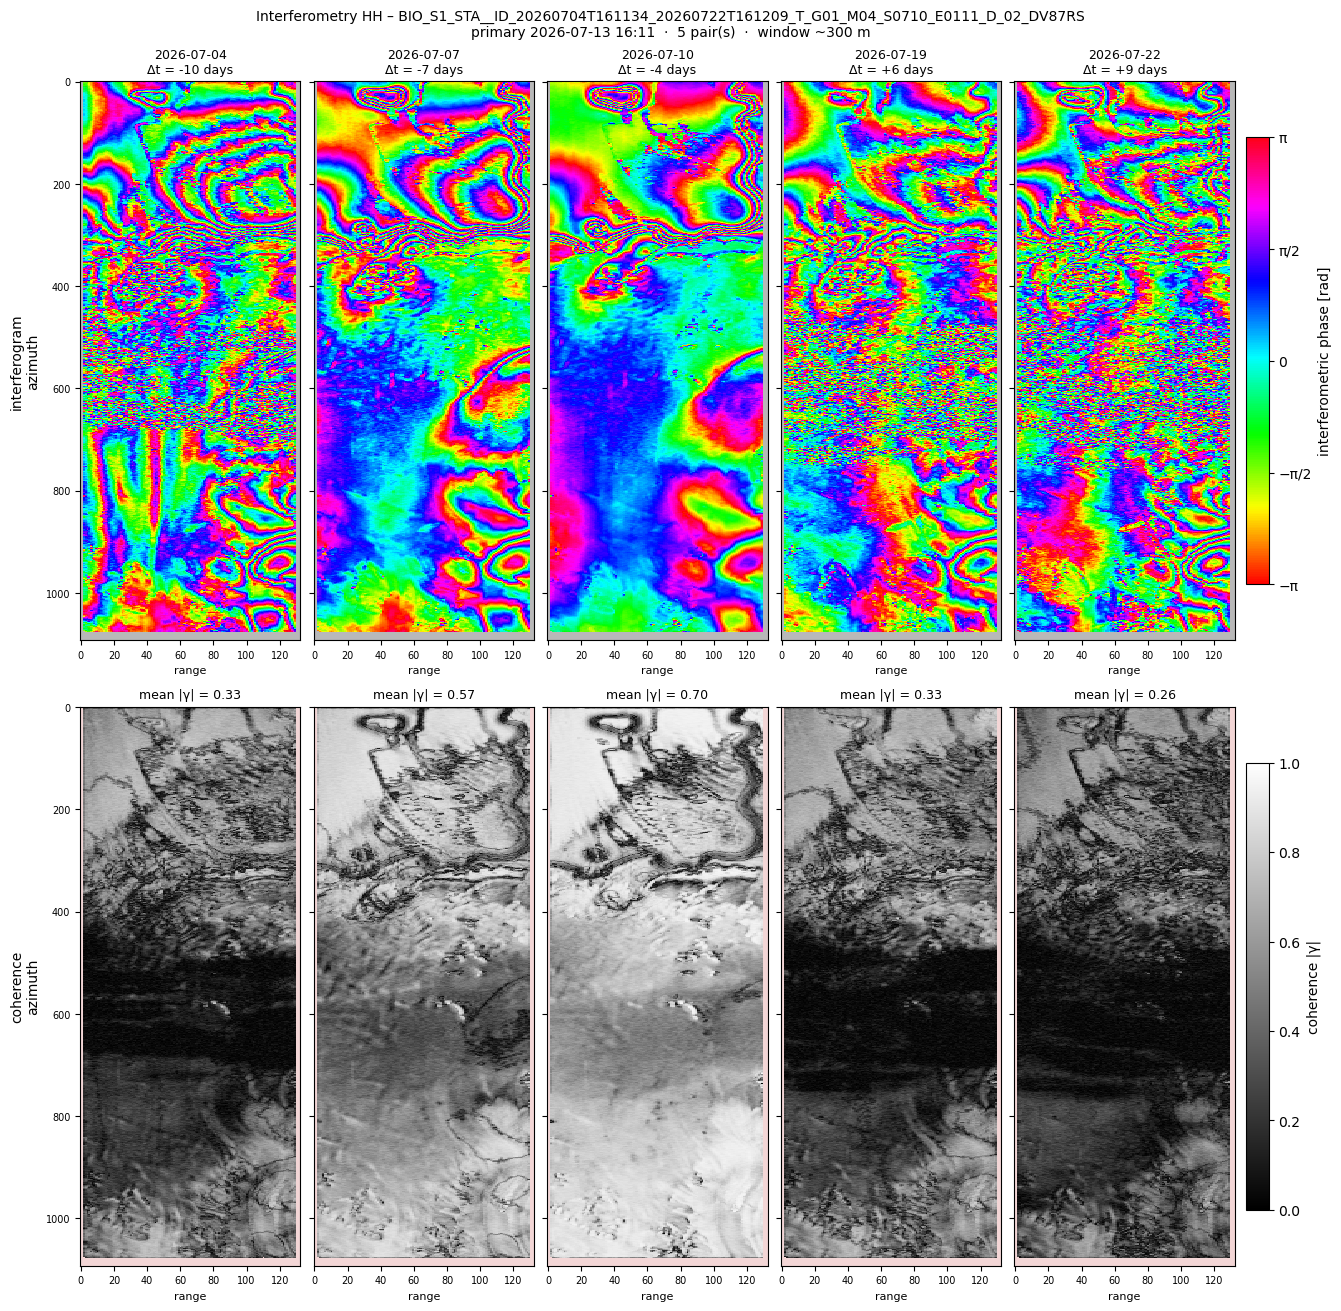

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_HH_interferometry.png

  HV
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-04 (Δt -10 d): mean |γ| 0.19, median 0.13
      phase mean +0.309 rad (+16.9 mm), std 2.863 rad, 2–98 % -3.007…+3.015 rad
  saved 20260713T161140_20260704T161134_HV_insar.tif
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-07 (Δt -7 d): mean |γ| 0.32, median 0.26
      phase mean -2.770 rad (-151.9 mm), std 2.624 rad, 2–98 % -2.999…+2.997 rad
  saved 20260713T161140_20260707T161136_HV_insar.tif
    flattening phase from coregistration_flatteningPhaseScreen
    calibrat

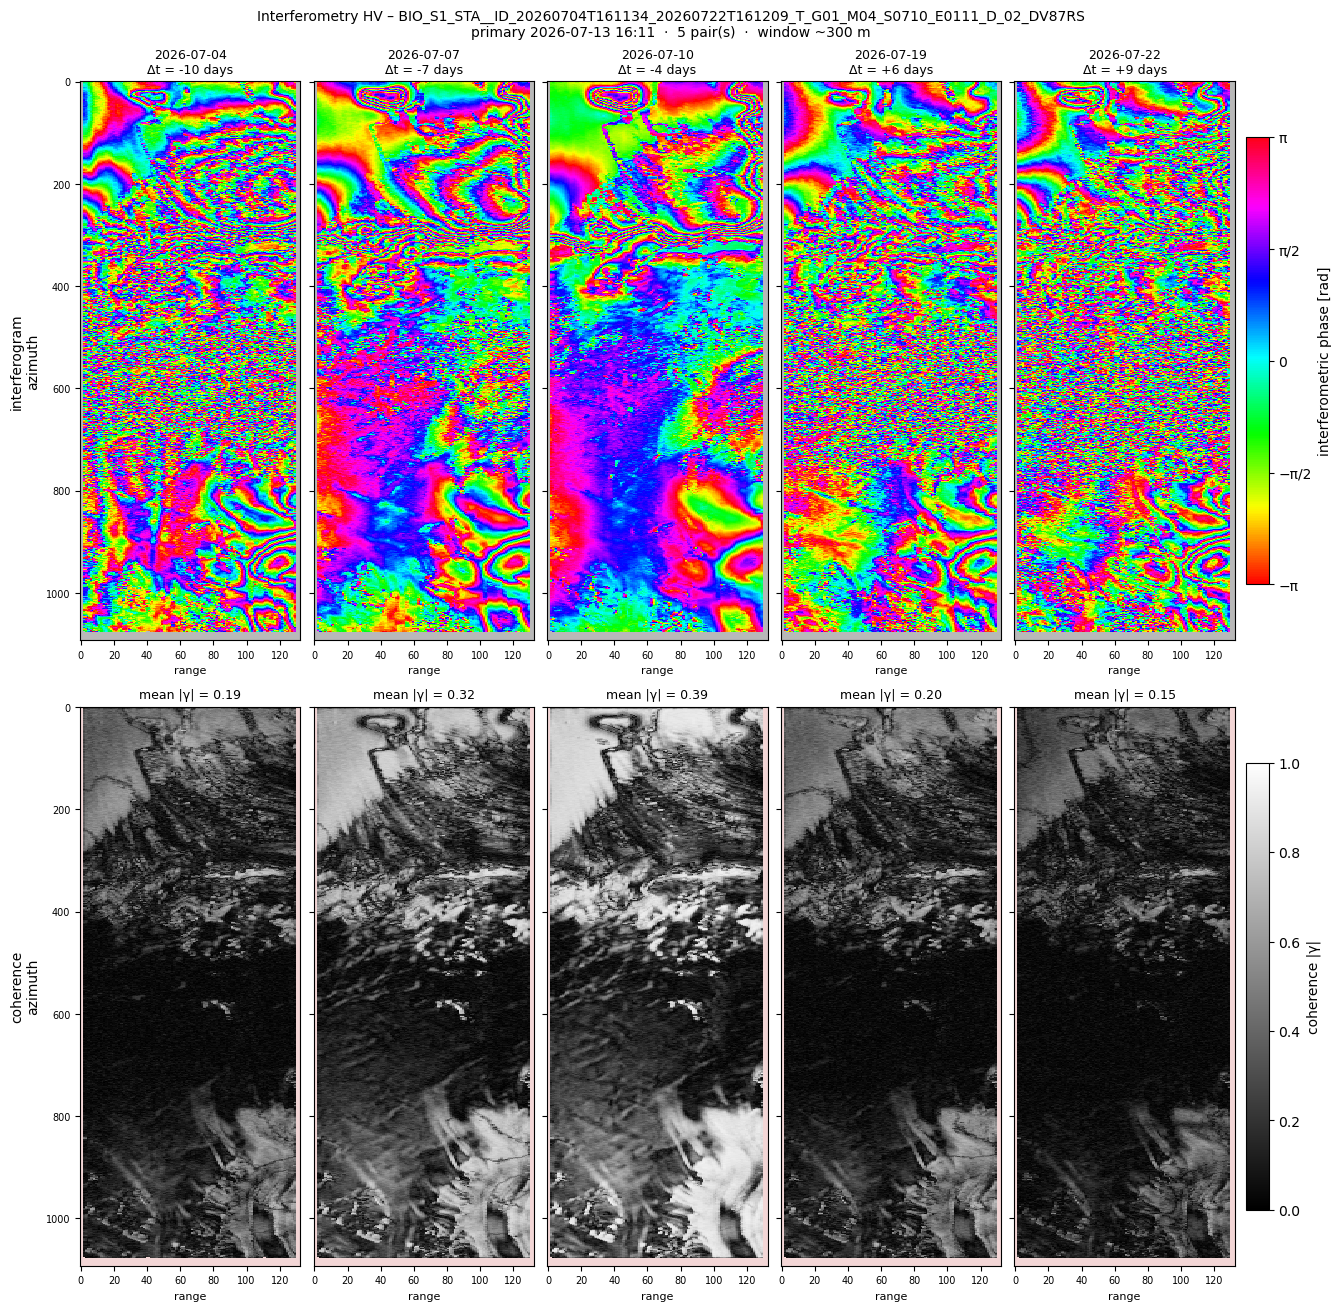

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_HV_interferometry.png

  VH
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-04 (Δt -10 d): mean |γ| 0.20, median 0.13
      phase mean +0.296 rad (+16.2 mm), std 2.859 rad, 2–98 % -3.005…+3.015 rad
  saved 20260713T161140_20260704T161134_VH_insar.tif
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-07 (Δt -7 d): mean |γ| 0.32, median 0.26
      phase mean -2.824 rad (-154.9 mm), std 2.636 rad, 2–98 % -2.997…+2.998 rad
  saved 20260713T161140_20260707T161136_VH_insar.tif
    flattening phase from coregistration_flatteningPhaseScreen
    calibrat

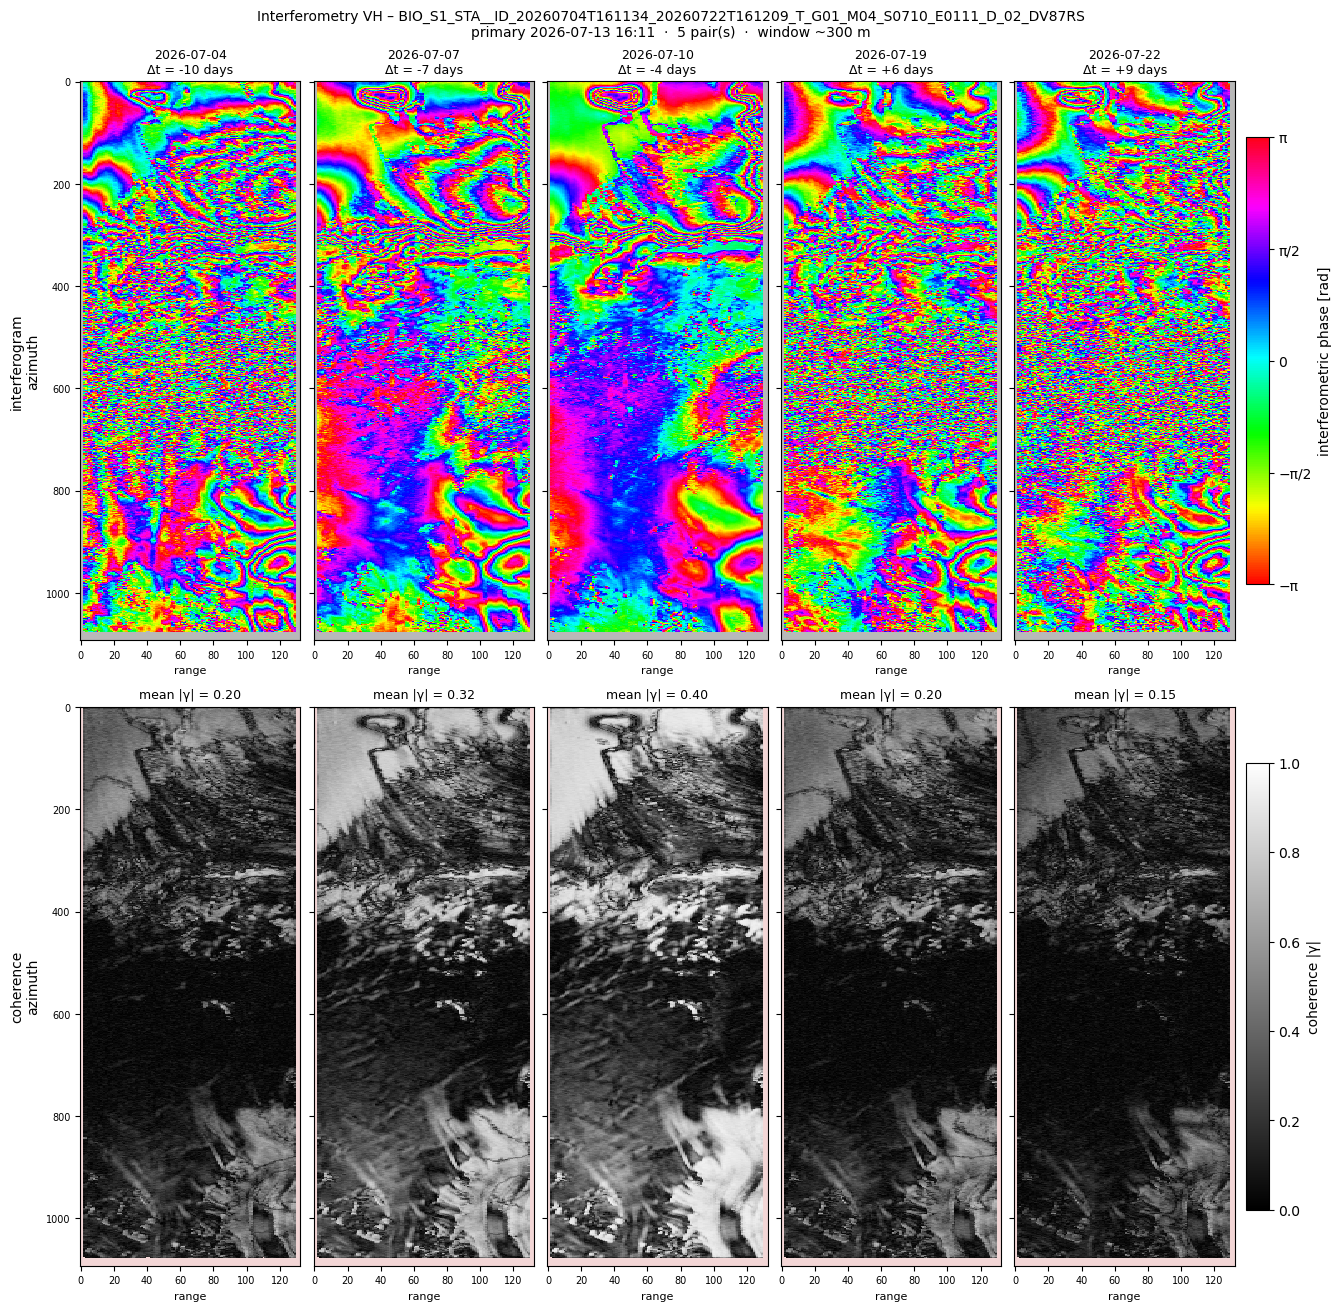

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_VH_interferometry.png

  VV
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-04 (Δt -10 d): mean |γ| 0.33, median 0.31
      phase mean +0.368 rad (+20.2 mm), std 2.756 rad, 2–98 % -3.008…+3.019 rad
  saved 20260713T161140_20260704T161134_VV_insar.tif
    flattening phase from coregistration_flatteningPhaseScreen
    calibration phase from skpPhaseCalibration_skpCalibrationPhaseScreen
    2026-07-13 × 2026-07-07 (Δt -7 d): mean |γ| 0.58, median 0.59
      phase mean +0.168 rad (+9.2 mm), std 1.904 rad, 2–98 % -2.968…+2.948 rad
  saved 20260713T161140_20260707T161136_VV_insar.tif
    flattening phase from coregistration_flatteningPhaseScreen
    calibratio

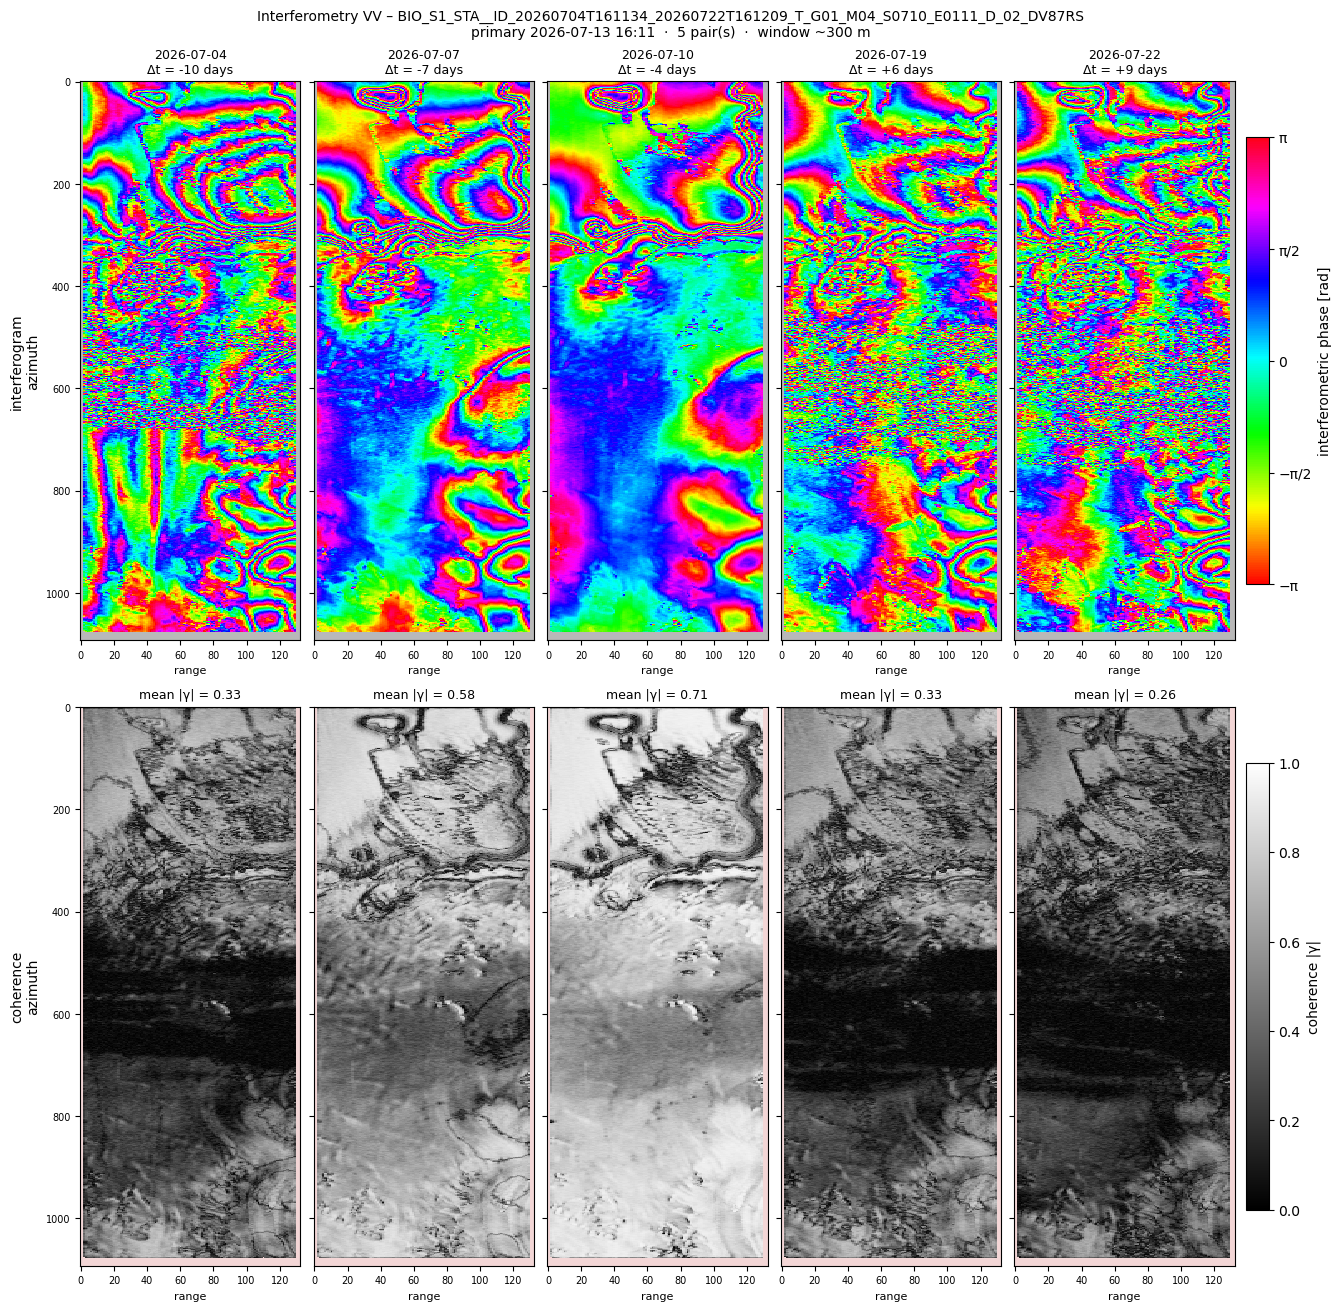

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_VV_interferometry.png

  summary: /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_141344_insar/BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS/interferometry/BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_coherence_summary.csv

Finished. Results in /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_141344_insar


In [15]:
run_dir = pu.new_run_folder(OUTPUT_DIR, "insar", NEW_RUN_FOLDER, RUN_LABEL,
                            settings=dict(stacks=STACKS, secondaries=SECONDARIES, polarisations=POLARISATIONS,
                                          window_m=WINDOW_M, phase_correction=PHASE_CORRECTION,
                                          interferogram_range=INTERFEROGRAM_RANGE, geotiff=SAVE_GEOTIFF))
pu.run_interferometry(stacks, run_dir, which_stacks=STACKS, secondaries=SECONDARIES, pols=POLARISATIONS,
                      window_m=WINDOW_M, correction=PHASE_CORRECTION, geotiff=SAVE_GEOTIFF, show=SHOW_FIGURES,
                      phase_range=INTERFEROGRAM_RANGE)

## 7.5 Diagnostics: check the phase processing
Per stack, this section shows what the processing has done to the phase:
1. **All processing flags** in the XML files of the primary, and the flags that differ in the secondaries.
2. **All LUT layers** with their value range.
3. **LUT phases** of every acquisition: the flattening phase (wrapped, the coloured fringes of the geometry, removed with `PHASE_CORRECTION = "flattening"`) and the SKP calibration screen (also removed with `"flattening+calibration"`).
4. **ESA's quicklooks** of the interferogram and coherence (`preview/*itf*ql.png`, `*coh*ql.png`) to compare with 7.4.

`DIAGNOSTIC_STACKS`: `"all"`, stack names, stack IDs or numbers, as `STACKS` in 7.3. Uses `OUTPUT_DIR` from 7.1 and `NEW_RUN_FOLDER`, `RUN_LABEL` and `SHOW_FIGURES` from 7.3.

In [ ]:
DIAGNOSTIC_STACKS = "all"

diag_dir = pu.new_run_folder(OUTPUT_DIR, "insar_diagnostics", NEW_RUN_FOLDER, RUN_LABEL,
                             settings=dict(stacks=DIAGNOSTIC_STACKS))
pu.run_insar_diagnostics(stacks, diag_dir, which_stacks=DIAGNOSTIC_STACKS, show=SHOW_FIGURES)

## 7.6 Extra: find the primary of each stack
The primary is the coregistration reference of the stack (`isCoregistrationPrimary` in the product XML).
`PRIMARY_STACKS`: `"all"`, stack names such as `["stack_01"]`, or numbers such as `[0, 2]`.

In [ ]:
PRIMARY_STACKS = "all"

primaries = pu.print_primaries(stacks, PRIMARY_STACKS)